<a href="https://colab.research.google.com/github/AchRef864/ML_Labs/blob/main/Simple_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import

In [ ]:
# Matplotlibbb
import matplotlib.pyplot as plt
# Tensorflow
import tensorflow as tf
# Numpy and Pandas
import numpy as np
import pandas as pd
# Ohter import
import sys

## Be sure to used Tensorflow 2.0

In [ ]:
assert hasattr(tf, "function") # Be sure to use tensorflow 2.0

## Load the dataset: Fashion MNIST

![](https://storage.googleapis.com/kaggle-datasets-images/2243/3791/9384af51de8baa77f6320901f53bd26b/dataset-cover.png)

In [ ]:
from sklearn.preprocessing import StandardScaler

# Fashio MNIST
fashion_mnist = tf.keras.datasets.fashion_mnist
(images, targets), (images_test, targets_test) = fashion_mnist.load_data()

# Get only a subpart of the dataset
images = images[:10000]
targets = targets [:10000]

# Reshape the dataset and convert to float
images = images.reshape(-1, 784)
images = images.astype(float)
images_test = images_test.reshape(-1, 784)
images_test = images_test.astype(float)

scaler = StandardScaler()
images = scaler.fit_transform(images)
images_test = scaler.transform(images_test)

print(images.shape)
print(targets.shape)

4431872/4422102 [==============================] - 0s 0us/step
(10000, 784)
(10000,)


## Plot one of the data

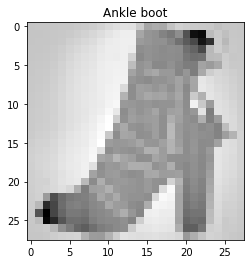

In [ ]:
targets_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal",
                 "Shirt", "Sneaker", "Bag", "Ankle boot"
]
# Plot one image
plt.imshow(np.reshape(images[11], (28, 28)), cmap="binary")
plt.title(targets_names[targets[11]])
plt.show()

# Create the model
![](https://github.com/thibo73800/tensorflow2.0-examples/blob/master/images/simple_nn.png?raw=1)

# Create the model

In [ ]:
# Flatten
model = tf.keras.models.Sequential()

# Add the layers
model.add(tf.keras.layers.Dense(256, activation="relu"))
model.add(tf.keras.layers.Dense(128, activation="relu"))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

model_output = model.predict(images[0:1])
print(model_output, targets[0:1])

[[0.17841996 0.1607249  0.05364167 0.06948797 0.00874101 0.06142465
  0.33683017 0.05304671 0.05347583 0.02420715]] [9]


## Model Summary

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               200960    
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dense_2 (Dense)             (None, 10)                1290      
                                                                 
Total params: 235,146
Trainable params: 235,146
Non-trainable params: 0
_________________________________________________________________


## Compile the model

In [ ]:
# Compile the model
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="sgd",
    metrics=["accuracy"]
)

## Train the model

In [ ]:
history = model.fit(images, targets, epochs=10, validation_split=0.2)

Epoch 1/10
250/250 [==============================] - 2s 4ms/step - loss: 0.8937 - accuracy: 0.7003 - val_loss: 0.6476 - val_accuracy: 0.7800
Epoch 2/10
250/250 [==============================] - 1s 3ms/step - loss: 0.5405 - accuracy: 0.8101 - val_loss: 0.5439 - val_accuracy: 0.8175
Epoch 3/10
250/250 [==============================] - 1s 4ms/step - loss: 0.4577 - accuracy: 0.8394 - val_loss: 0.4843 - val_accuracy: 0.8250
Epoch 4/10
250/250 [==============================] - 1s 3ms/step - loss: 0.4075 - accuracy: 0.8564 - val_loss: 0.4664 - val_accuracy: 0.8315
Epoch 5/10
250/250 [==============================] - 1s 3ms/step - loss: 0.3738 - accuracy: 0.8700 - val_loss: 0.4523 - val_accuracy: 0.8405
Epoch 6/10
250/250 [==============================] - 1s 4ms/step - loss: 0.3476 - accuracy: 0.8789 - val_loss: 0.4487 - val_accuracy: 0.8415
Epoch 7/10
250/250 [==============================] - 1s 4ms/step - loss: 0.3229 - accuracy: 0.8880 - val_loss: 0.4277 - val_accuracy: 0.8510
Epoch 

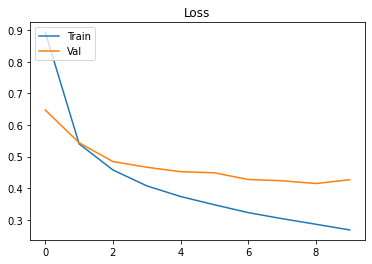

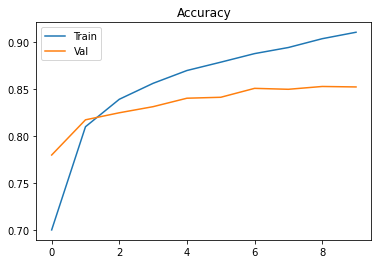

In [ ]:
loss_curve = history.history["loss"]
acc_curve = history.history["accuracy"]

loss_val_curve = history.history["val_loss"]
acc_val_curve = history.history["val_accuracy"]

plt.plot(loss_curve, label="Train")
plt.plot(loss_val_curve, label="Val")
plt.legend(loc='upper left')
plt.title("Loss")
plt.show()

plt.plot(acc_curve, label="Train")
plt.plot(acc_val_curve, label="Val")
plt.legend(loc='upper left')
plt.title("Accuracy")
plt.show()

In [ ]:
loss, acc = model.evaluate(images_test, targets_test)
print("Test Loss", loss)
print("Test Accuracy", acc)

10000/10000 [==============================] - 0s 35us/sample - loss: 0.6163 - accuracy: 0.7856
Test Loss 0.6163142968177795
Test Accuracy 0.7856
